In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
from io import BytesIO
from PIL import Image
import sys 
sys.path.extend(['/Users/amonast/Documents/GitHub/zlab_miniscope'])
from load_traces import get_tuned_df, get_co_tuned_cells

matplotlib.rcParams['svg.fonttype'] = 'none'

data_dir = '/Users/amonast/Desktop/miniscope/data'
CATEGORIES = ['Aggressive', 'Pro-Social', 'Social Avoidance','Other']

color_map_categories = {
    'Aggressive':       '#fe0806',
    'Pro-Social':       '#55a0fb',
    'Social Avoidance': '#b856d7',
    'Other':          "#777777",
    'Mixed':            "#05FD0D",
}

In [2]:
#nimals = sorted(pd.read_csv(f"{data_dir}/p_values_C1M1_R1.csv")['animal'].unique())  # or list them explicitly
animals =   ['C1F2','C1M1','C1M2', 'C2F1','C2M4', 'C3F3', 'C3F4', 
                'C3M2','C3M3', 'C3M4']
tuned, df = get_tuned_df(animals, data_dir)
zscores = df.xs('zscore', level='metric').reset_index()

tuned

,animal,session,behavior_type,tuned_cells
0,C1F2,R1,Aggressive,"[0, 13, 19, 33, 59]"
1,C1F2,R1,Other,[19]
2,C1F2,R1,Pro-Social,"[3, 7, 9, 17, 19, 20, 22, 23, 26, 31, 37, 44, ..."
3,C1F2,R1,Social Avoidance,"[6, 17, 19, 33, 38, 58, 59]"
4,C1F2,R2,Aggressive,"[2, 7, 8, 10, 13, 18, 19, 21, 22, 30, 32, 36]"
...,...,...,...,...
66,C3M4,R1,Social Avoidance,"[16, 17]"
67,C3M4,R2,Aggressive,"[27, 42, 49, 51]"
68,C3M4,R2,Other,"[3, 4, 28, 57, 58]"
69,C3M4,R2,Pro-Social,"[0, 5, 6, 7, 8, 11, 14, 15, 17, 18, 20, 26, 27..."


In [3]:
# Cells significantly (p<=0.05) and positively (z>0) tuned to BOTH Aggressive and Pro-Social
co_tuned = get_co_tuned_cells(df, 'Aggressive', 'Pro-Social', exclude_animals=['C2M4', 'C2F1'])

co_tuned_cell_ids = {
    f"{row['animal']}_{row['session']}_{c}"
    for _, row in co_tuned.iterrows()
    for c in row['co_tuned_cells']
}

co_tuned

,animal,session,co_tuned_cells
0,C1F2,R1,[19]
1,C1F2,R2,"[7, 8, 36]"
2,C1M2,R2,[]
3,C3M2,R1,[]
4,C3M2,R2,"[21, 43, 47]"
5,C3M3,R1,[19]
6,C3M3,R2,"[15, 19]"
7,C3M4,R1,[]
8,C3M4,R2,"[27, 42, 49]"


## Per-animal cluster maps

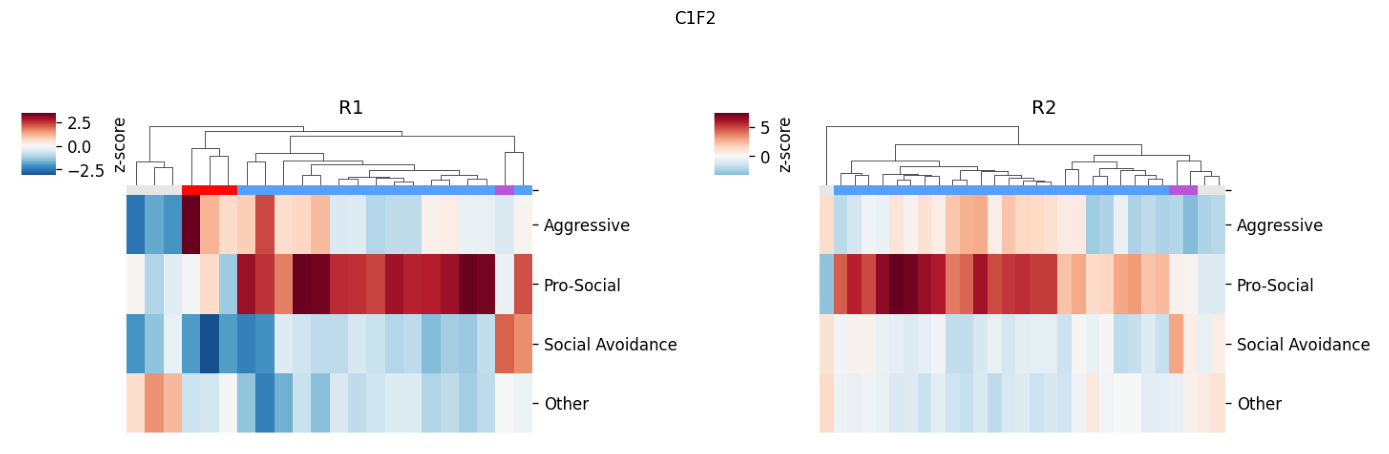

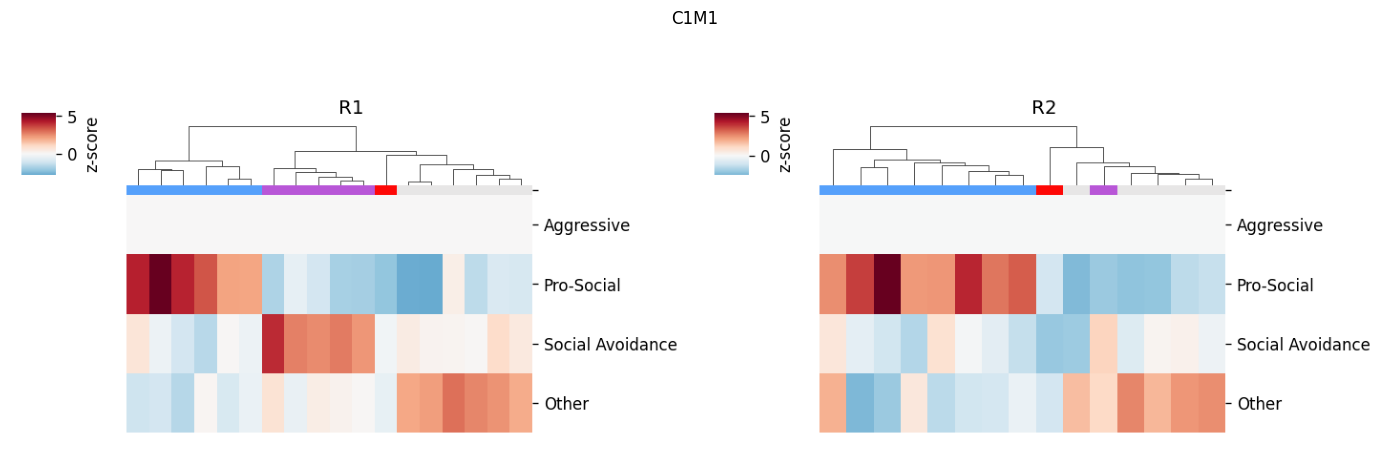

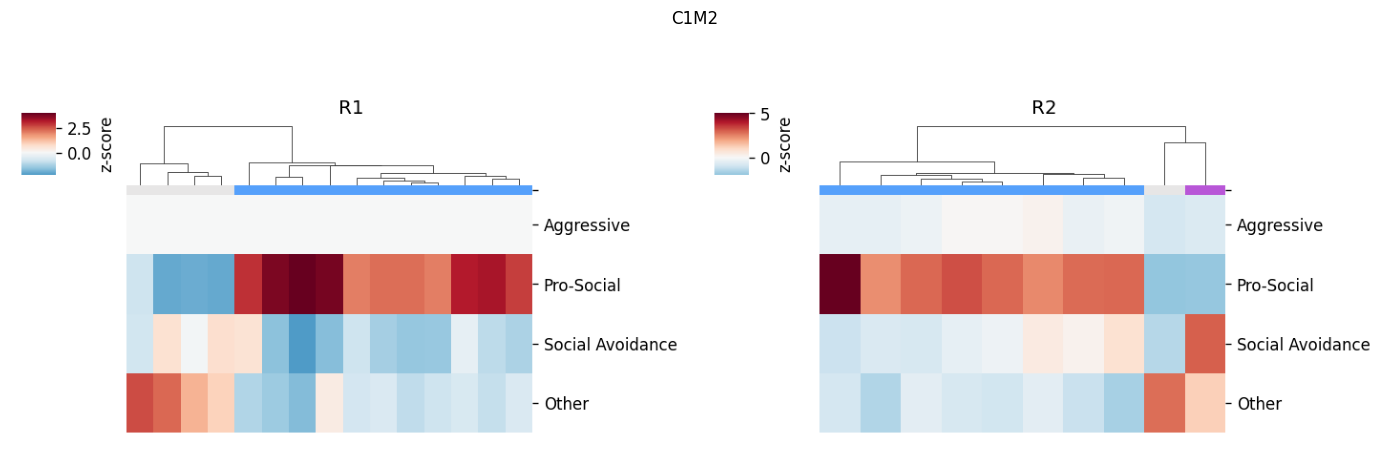

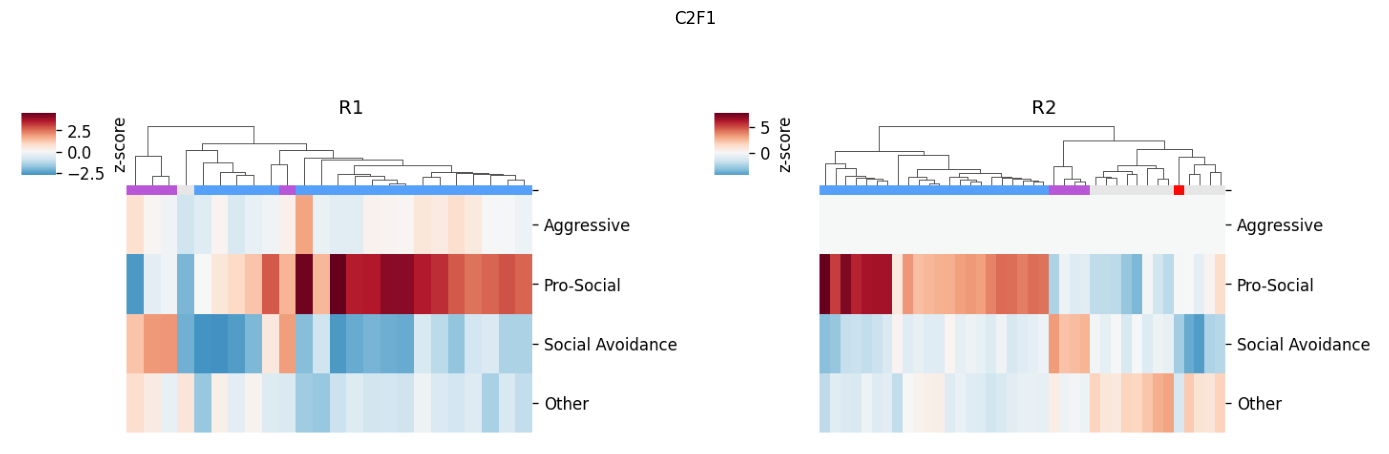

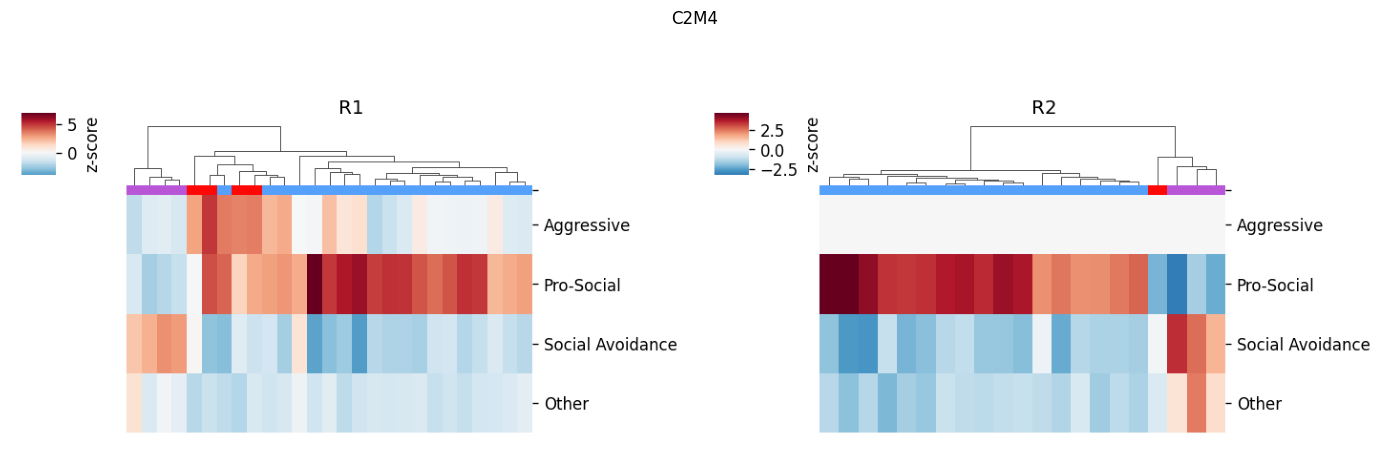

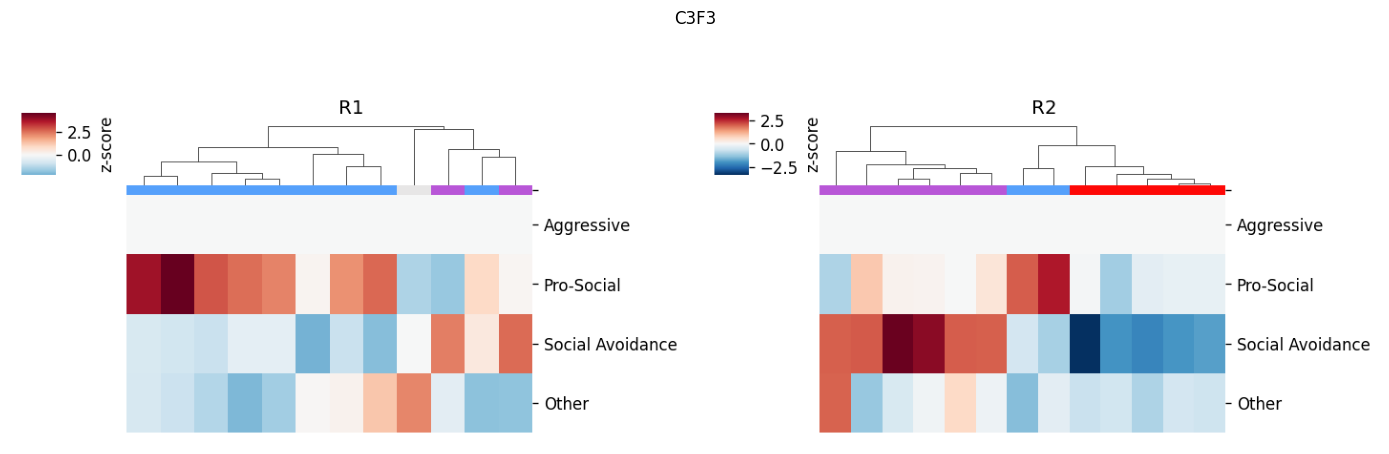

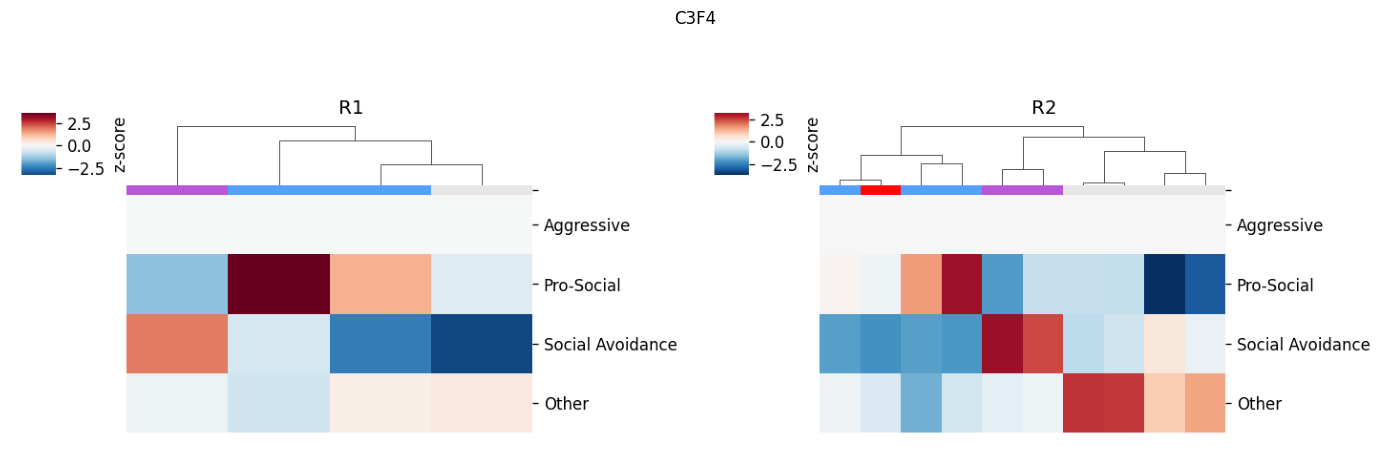

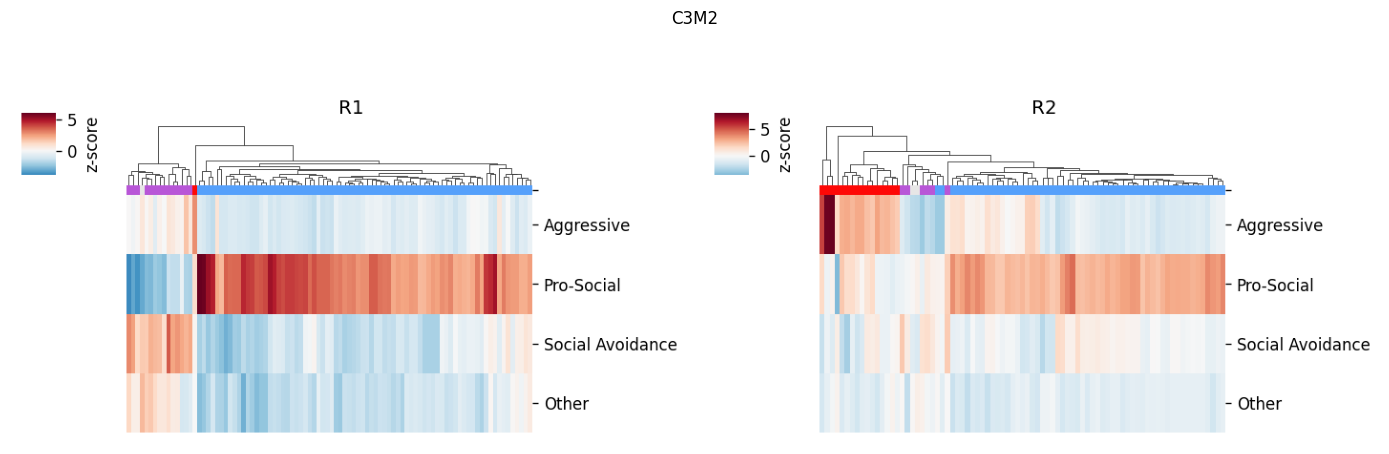

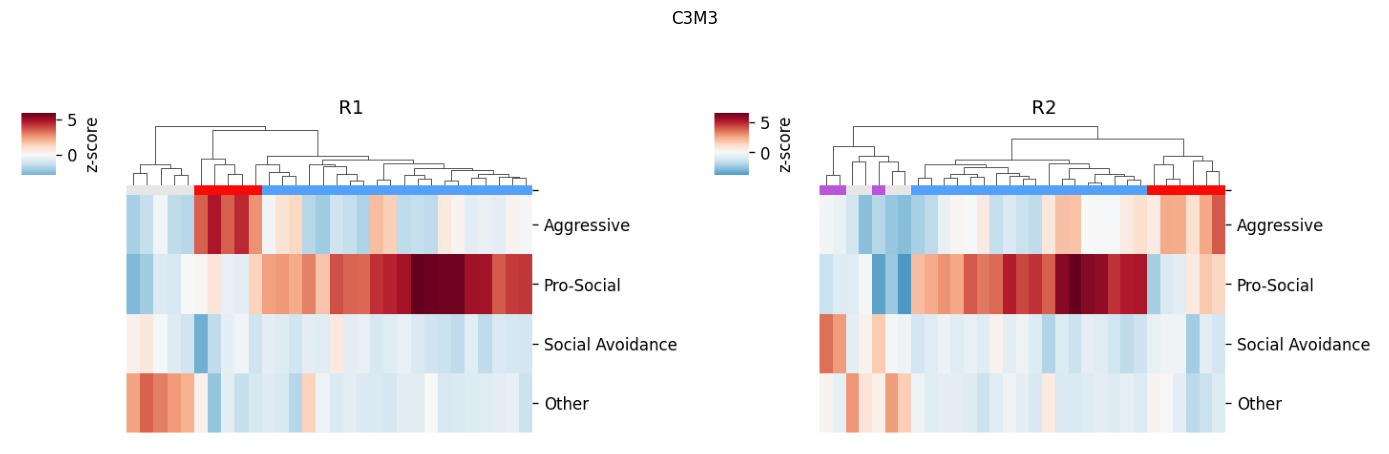

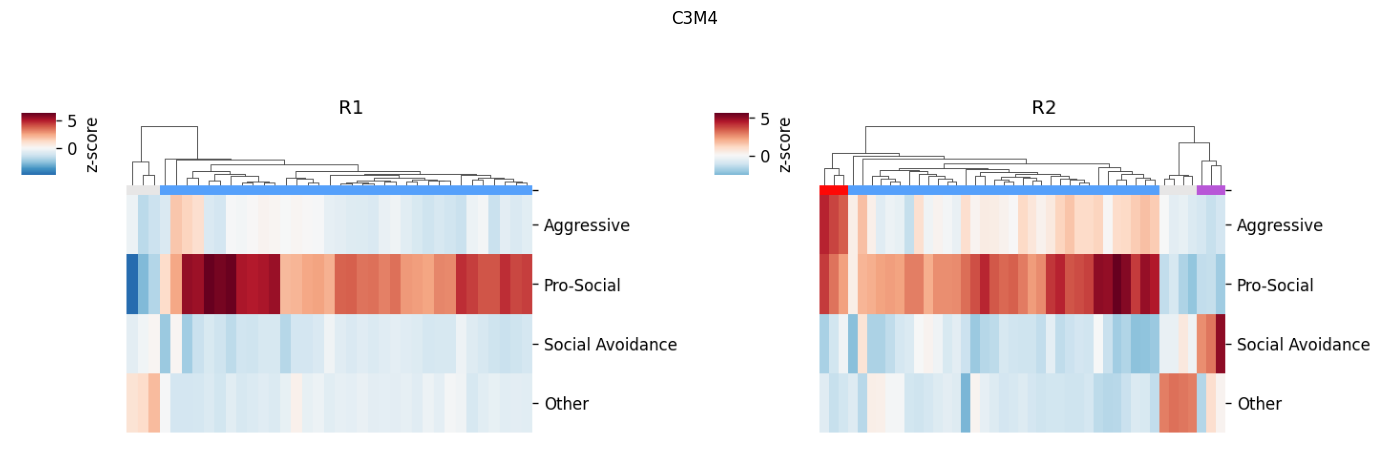

In [4]:
def make_clustermap_img(animal, session, color_map):
    grp = tuned[(tuned['animal'] == animal) & (tuned['session'] == session)]
    all_cells = sorted(set(c for cells in grp['tuned_cells'] for c in cells))
    if len(all_cells) < 2:
        return None

    rows = []
    for bt in CATEGORIES:
        z_row = zscores[
            (zscores['animal'] == animal) &
            (zscores['session'] == session) &
            (zscores['behavior_type'] == bt)
        ]
        if z_row.empty:
            rows.append(pd.Series(0.0, index=all_cells, name=bt))
        else:
            rows.append(z_row[all_cells].iloc[0].rename(bt))

    clust_df = pd.DataFrame(rows).fillna(0)
    col_colors = clust_df.idxmax(axis=0).map(color_map)
    g = sns.clustermap(clust_df, row_cluster=False, col_colors=col_colors,
                       cmap='RdBu_r', center=0, xticklabels=False,
                       figsize=(6, 3), cbar_kws={'label': 'z-score'})
    g.fig.suptitle(session, y=1.02)
    buf = BytesIO()
    g.fig.savefig(buf, format='png', bbox_inches='tight', dpi=120)
    plt.close(g.fig)
    buf.seek(0)
    return Image.open(buf)


for animal in sorted(tuned['animal'].unique()):
    img_r1 = make_clustermap_img(animal, 'R1', color_map_categories)
    img_r2 = make_clustermap_img(animal, 'R2', color_map_categories)
    imgs = [(img, lbl) for img, lbl in [(img_r1, 'R1'), (img_r2, 'R2')] if img is not None]
    if not imgs:
        continue
    fig, axes = plt.subplots(1, len(imgs), figsize=(7 * len(imgs), 5))
    if len(imgs) == 1:
        axes = [axes]
    for ax, (img, lbl) in zip(axes, imgs):
        ax.imshow(img)
        ax.axis('off')
    fig.suptitle(animal, fontsize=12)
    plt.tight_layout()
    plt.show()

## All animals pooled

/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_56126/1598037782.py:76: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


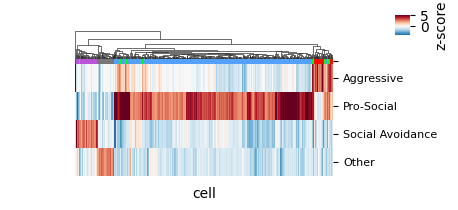

In [13]:
Z_THR = 2.0

pvalues = df.xs('pval', level='metric').reset_index()

# First pass: for each cell, track EVERY behavior it passes p<0.05 & z>Z_THR for
from collections import defaultdict
qualifying_cell_bts = defaultdict(set)
for (animal, session), grp in tuned.groupby(['animal', 'session']):
    all_cells = sorted(set(c for cells in grp['tuned_cells'] for c in cells))
    for bt in CATEGORIES:
        z_row = zscores[
            (zscores['animal'] == animal) &
            (zscores['session'] == session) &
            (zscores['behavior_type'] == bt)]
        p_row = pvalues[
            (pvalues['animal'] == animal) &
            (pvalues['session'] == session) &
            (pvalues['behavior_type'] == bt)]
        for c in all_cells:
            z = float(z_row[c].iloc[0]) if not z_row.empty and c in z_row.columns else 0.0
            p = float(p_row[c].iloc[0]) if not p_row.empty and c in p_row.columns else 1.0
            if p < 0.05 and z > Z_THR:
                qualifying_cell_bts[f"{animal}_{session}_{c}"].add(bt)

# Merge in Aggressive+Pro-Social co-tuned cells even if they don't individually clear Z_THR
qualifying_cells = set(qualifying_cell_bts) | co_tuned_cell_ids

def cell_color(cell_id, bt_map=qualifying_cell_bts, co_tuned=co_tuned_cell_ids, palette=color_map_categories):
    if cell_id in co_tuned:
        return palette['Mixed']
    bts = bt_map.get(cell_id, set())
    if len(bts) > 1:
        return palette['Mixed']
    return palette[next(iter(bts))]

# Second pass: for qualifying cells, store raw z-scores for all behaviors
all_records = []
for (animal, session), grp in tuned.groupby(['animal', 'session']):
    all_cells = sorted(set(c for cells in grp['tuned_cells'] for c in cells))
    if not all_cells:
        continue
    for bt in CATEGORIES:
        z_row = zscores[
            (zscores['animal'] == animal) &
            (zscores['session'] == session) &
            (zscores['behavior_type'] == bt)]
        for c in all_cells:
            cell_id = f"{animal}_{session}_{c}"
            if cell_id not in qualifying_cells:
                continue
            val = float(z_row[c].iloc[0]) if not z_row.empty and c in z_row.columns else 0.0
            all_records.append({'cell': cell_id, 'behavior_type': bt, 'zscore': val})

clust_df = (pd.DataFrame(all_records)
              .pivot_table(index='cell', columns='behavior_type', values='zscore', fill_value=0)
              .reindex(columns=CATEGORIES, fill_value=0)
              .T)

col_colors = pd.Series([cell_color(c) for c in clust_df.columns], index=clust_df.columns)

g = sns.clustermap(
    clust_df,
    metric='euclidean',
    row_cluster=False,
    col_colors=col_colors,
    cmap='RdBu_r',
    center=0,
    vmax=5,
    figsize=(5,2),
    xticklabels=False,
    cbar_kws={'label': 'z-score'},
    cbar_pos=(.8,.9, .03, .1))
g.ax_heatmap.tick_params(labelsize=8)
g.ax_heatmap.set_ylabel('', fontsize=8)
#plt.suptitle(f'Z-scores of significantly tuned cells (p<0.05, z>{Z_THR}) — all animals')
plt.tight_layout()
plt.savefig('/Users/amonast/Desktop/miniscope/figures/zscores_tunedcells_clustermap_zpos.svg', transparent=True)

In [6]:
# Animal/session pairs with at least one Aggressive-tuned cell
agg_sessions = {
    (row['animal'], row['session'])
    for _, row in tuned[tuned['behavior_type'] == 'Aggressive'].iterrows()
    if len(row['tuned_cells']) > 0
}

all_records_agg = []
for (animal, session), grp in tuned.groupby(['animal', 'session']):
    if (animal, session) not in agg_sessions:
        continue
    all_cells = sorted(set(c for cells in grp['tuned_cells'] for c in cells))
    if not all_cells:
        continue
    for bt in CATEGORIES:
        z_row = zscores[
            (zscores['animal'] == animal) &
            (zscores['session'] == session) &
            (zscores['behavior_type'] == bt)]
        for c in all_cells:
            cell_id = f"{animal}_{session}_{c}"
            if cell_id not in qualifying_cells:   # reuse the p<0.05 & z>Z_THR filter from cell-6
                continue
            val = float(z_row[c].iloc[0]) if not z_row.empty and c in z_row.columns else 0.0
            all_records_agg.append({'cell': cell_id, 'behavior_type': bt, 'zscore': val})

clust_df_agg = (pd.DataFrame(all_records_agg)
              .pivot_table(index='cell', columns='behavior_type', values='zscore', fill_value=0)
              .reindex(columns=CATEGORIES, fill_value=0)
              .T)

col_colors_agg = pd.Series([cell_color(c) for c in clust_df_agg.columns], index=clust_df_agg.columns)


# Scatter plots

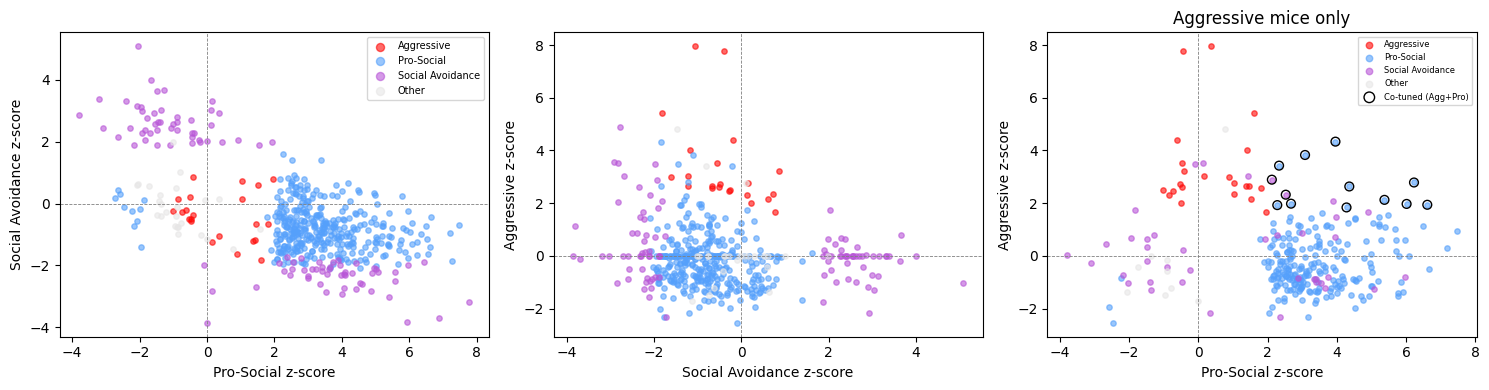

In [7]:
# clust_df is (behavior_type x cell) — transpose to get one row per cell
scatter_df = clust_df.T.copy()

# Color by the behavior each cell is actually tuned to (from tuned df)
cell_to_bt = {}
for _, row in tuned.iterrows():
    animal, session, bt = row['animal'], row['session'], row['behavior_type']
    for c in row['tuned_cells']:
        cell_id = f"{animal}_{session}_{c}"
        cell_to_bt[cell_id] = bt  # last write wins if a cell appears in multiple behaviors

scatter_df['tuned_to'] = scatter_df.index.map(cell_to_bt)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

pairs = [('Pro-Social', 'Social Avoidance'), ('Social Avoidance', 'Aggressive')]
for ax, (x_bt, y_bt) in zip(axes, pairs):
    for bt in CATEGORIES:
        sub = scatter_df[scatter_df['tuned_to'] == bt]
        ax.scatter(sub[x_bt], sub[y_bt], color=color_map_categories[bt],
                   alpha=0.6, s=15, label=bt)
    ax.axhline(0, color='gray', linewidth=0.6, linestyle='--')
    ax.axvline(0, color='gray', linewidth=0.6, linestyle='--')
    ax.set_xlabel(x_bt + ' z-score')
    ax.set_ylabel(y_bt + ' z-score')

axes[0].legend(fontsize=7, markerscale=1.5)

# Third panel: Aggressive vs Pro-Social, aggressive mice only
scatter_df_agg = clust_df_agg.T.copy()
scatter_df_agg['tuned_to'] = scatter_df_agg.index.map(cell_to_bt)
ax = axes[2]
for bt in CATEGORIES:
    sub = scatter_df_agg[scatter_df_agg['tuned_to'] == bt]
    ax.scatter(sub['Pro-Social'], sub['Aggressive'], color=color_map_categories[bt],
               alpha=0.6, s=15, label=bt)

# Highlight cells co-tuned to both Aggressive and Pro-Social (p<=0.05, z>0 for both)
co_sub = scatter_df_agg[scatter_df_agg.index.isin(co_tuned_cell_ids)]
ax.scatter(co_sub['Pro-Social'], co_sub['Aggressive'], facecolors='none',
           edgecolors='black', linewidths=1.0, s=40, label='Co-tuned (Agg+Pro)', zorder=5)

ax.axhline(0, color='gray', linewidth=0.6, linestyle='--')
ax.axvline(0, color='gray', linewidth=0.6, linestyle='--')
ax.set_xlabel('Pro-Social z-score')
ax.set_ylabel('Aggressive z-score')
ax.set_title('Aggressive mice only')
ax.legend(fontsize=6, markerscale=1.2)

plt.tight_layout()
plt.show()


# Aggressive only

/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_56126/2362879325.py:16: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


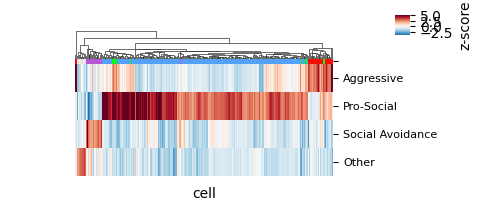

In [11]:
g = sns.clustermap(
    clust_df_agg,
    metric='euclidean',
    row_cluster=False,
    col_colors=col_colors_agg,
    cmap='RdBu_r',
    center=0,
    vmax=5,
    figsize=(5,2),
    xticklabels=False,
    cbar_kws={'label': 'z-score'},
    cbar_pos=(.8,.9, .03, .1))
g.ax_heatmap.tick_params(labelsize=8)
g.ax_heatmap.set_ylabel('', fontsize=8)
#plt.suptitle(f'Z-scores of significantly tuned cells (p<0.05, z>{Z_THR}) — all animals')
plt.tight_layout()